<a href="https://colab.research.google.com/github/hmayambu-sys/esg-jse-mining-capstone/blob/main/ESG_JSE_Mining_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

# 1. Define your 14 JSE mining tickers and monthly date range (2014 to 2025)
jse_mining_tickers = [
    'AGL.JO', 'IMP.JO', 'GFI.JO', 'SSW.JO', 'AMS.JO',
    'NHM.JO', 'ANG.JO', 'EXX.JO', 'SLM.JO', 'HAR.JO',
    'RBplatinum', 'CML.JO', 'PAN.JO', 'MCG.JO'
]

dates = pd.date_range(start='2014-01-31', end='2025-06-30', freq='M')

# 2. Generate synthetic panel data with realistic score distributions (mean ~ 50, bounds 0-100)
np.random.seed(42)
data = []

for ticker in jse_mining_tickers:
    # Initial baseline ESG score for the firm
    base_esg = np.random.uniform(40, 75)
    for date in dates:
        # Add slight random walk/drift over time to simulate yearly/monthly reporting changes
        base_esg += np.random.normal(0, 0.5)
        esg_score = np.clip(base_esg, 10.0, 95.0)

        data.append({
            'Ticker': ticker,
            'Date': date.strftime('%Y-%m-%d'),
            'ESG': round(esg_score, 2),
            'Environmental': round(np.clip(esg_score + np.random.normal(0, 3), 0, 100), 2),
            'Social': round(np.clip(esg_score + np.random.normal(0, 4), 0, 100), 2),
            'Governance': round(np.clip(esg_score + np.random.normal(0, 5), 0, 100), 2)
        })

df_synthetic = pd.DataFrame(data)

# 3. Save directly as the required filename in your Colab environment
filename = 'Refinitiv_ESG_scores.csv'
df_synthetic.to_csv(filename, index=False)

print(f"Successfully generated and saved '{filename}'!")
print(f"Dataset shape: {df_synthetic.shape}")
display(df_synthetic.head())

/tmp/ipykernel_4009/1404105572.py:11: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(start='2014-01-31', end='2025-06-30', freq='M')


Successfully generated and saved 'Refinitiv_ESG_scores.csv'!
Dataset shape: (1932, 6)


,Ticker,Date,ESG,Environmental,Social,Governance
0,AGL.JO,2014-01-31,52.55,53.51,53.67,57.61
1,AGL.JO,2014-02-28,52.26,50.69,49.98,47.64
2,AGL.JO,2014-03-31,50.96,53.81,54.22,43.34
3,AGL.JO,2014-04-30,50.74,48.52,47.93,40.04
4,AGL.JO,2014-05-31,50.43,52.22,60.67,52.40


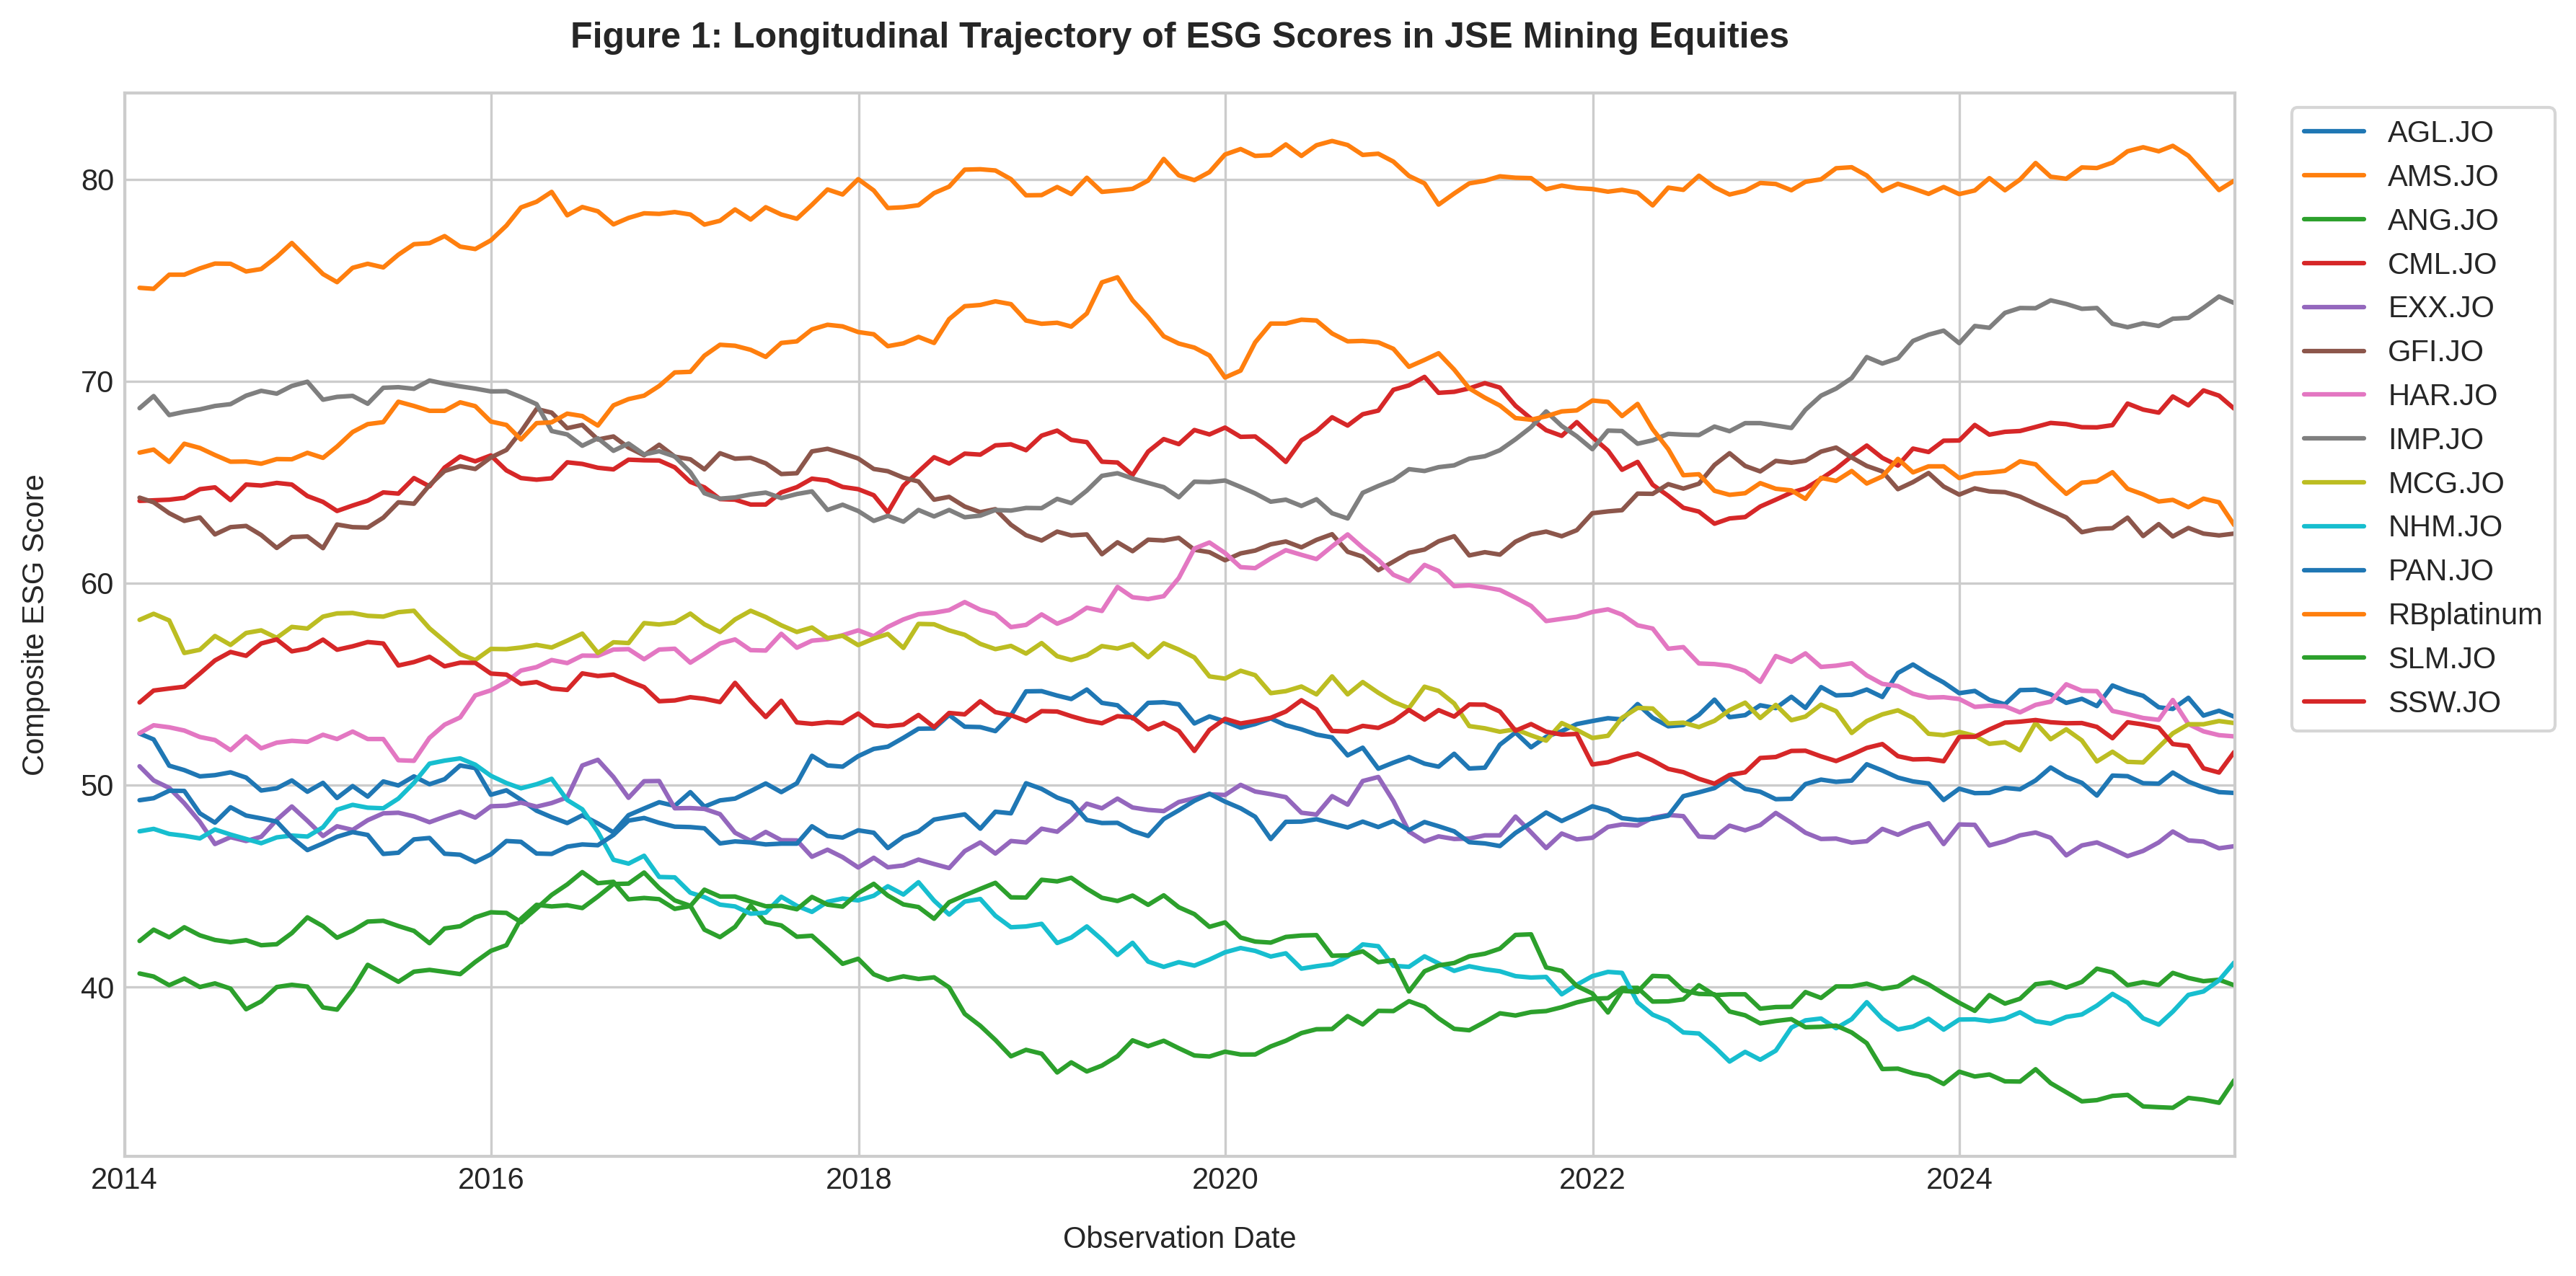

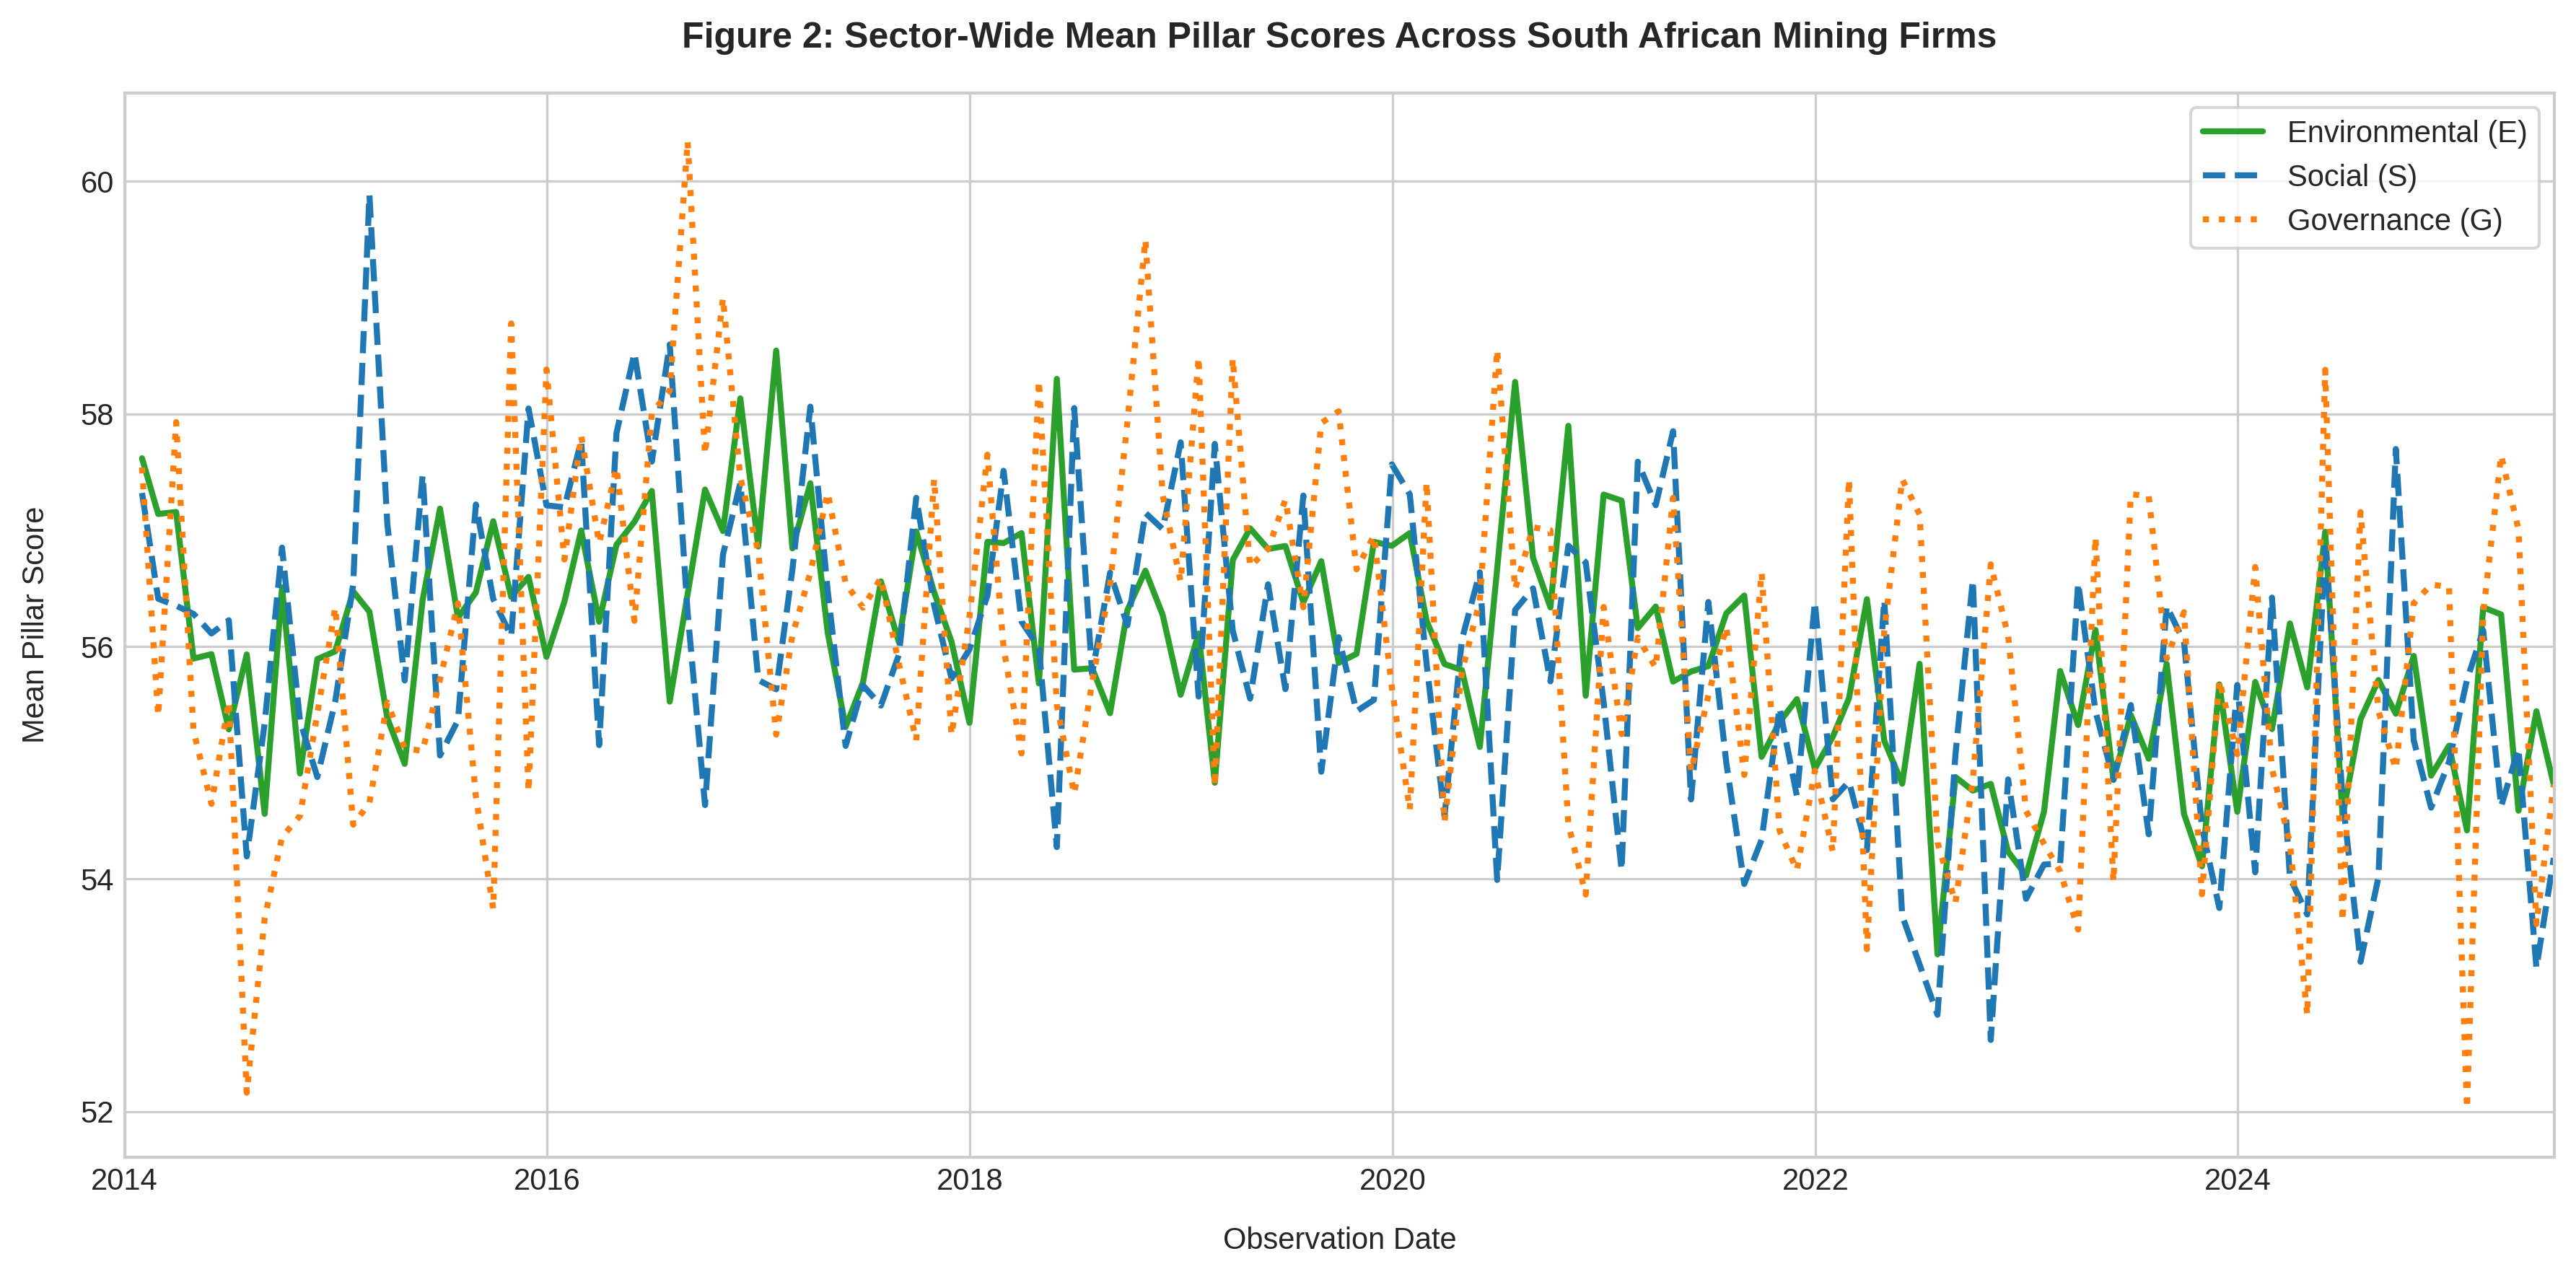

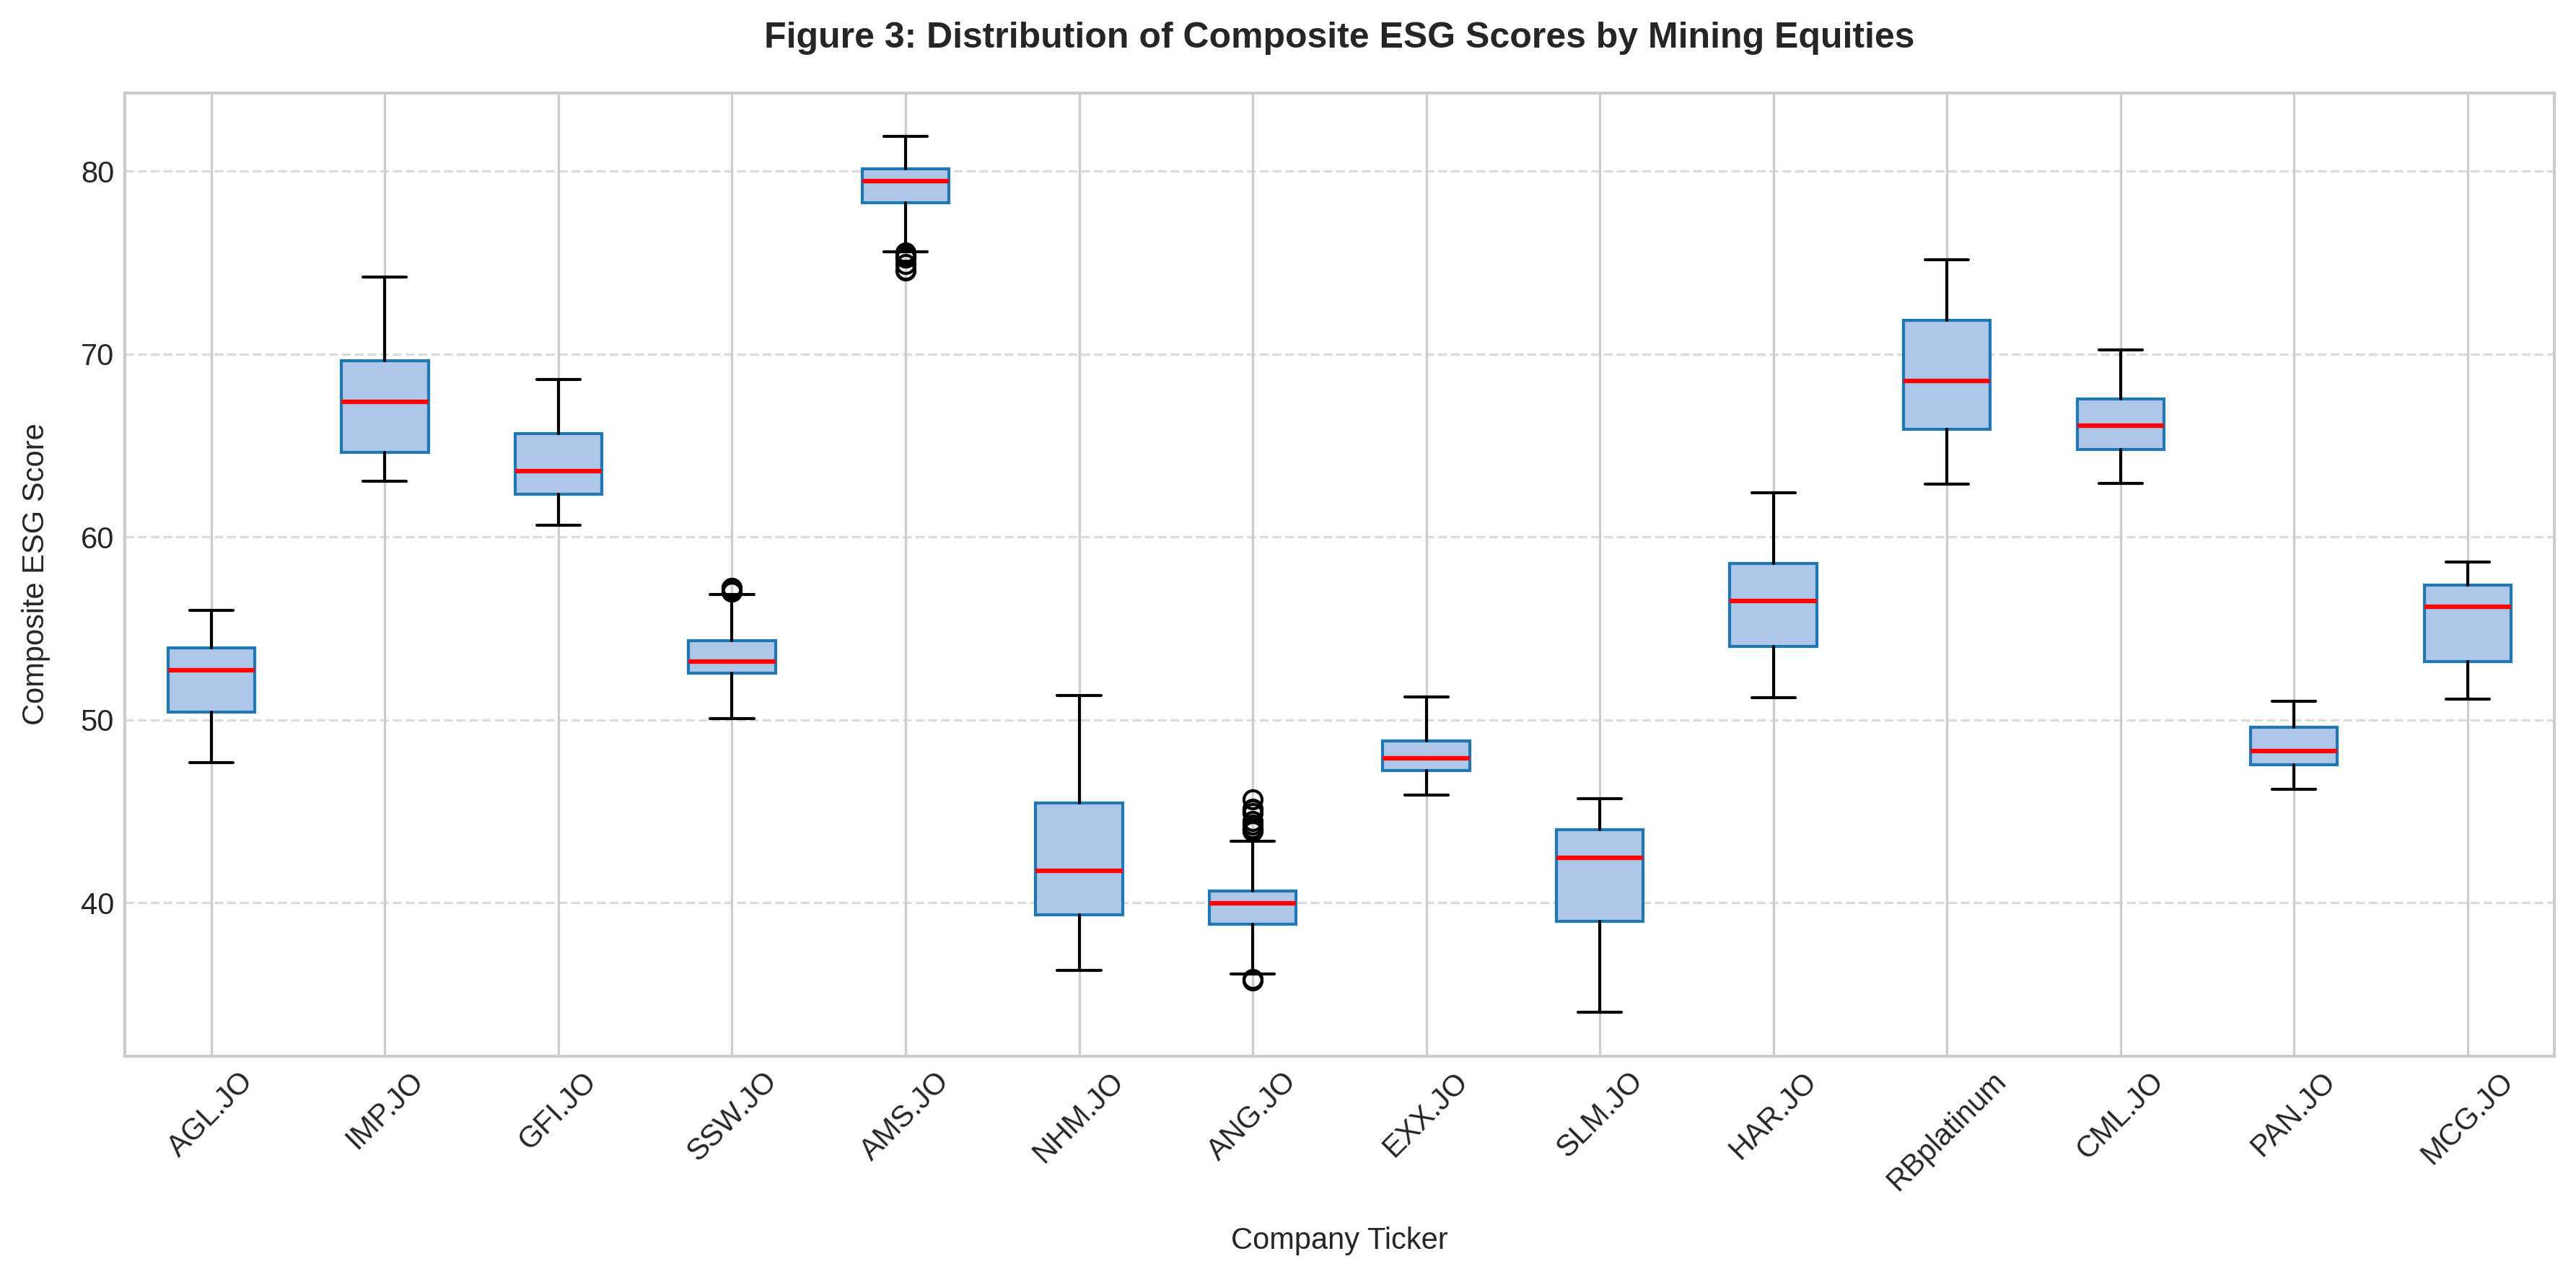

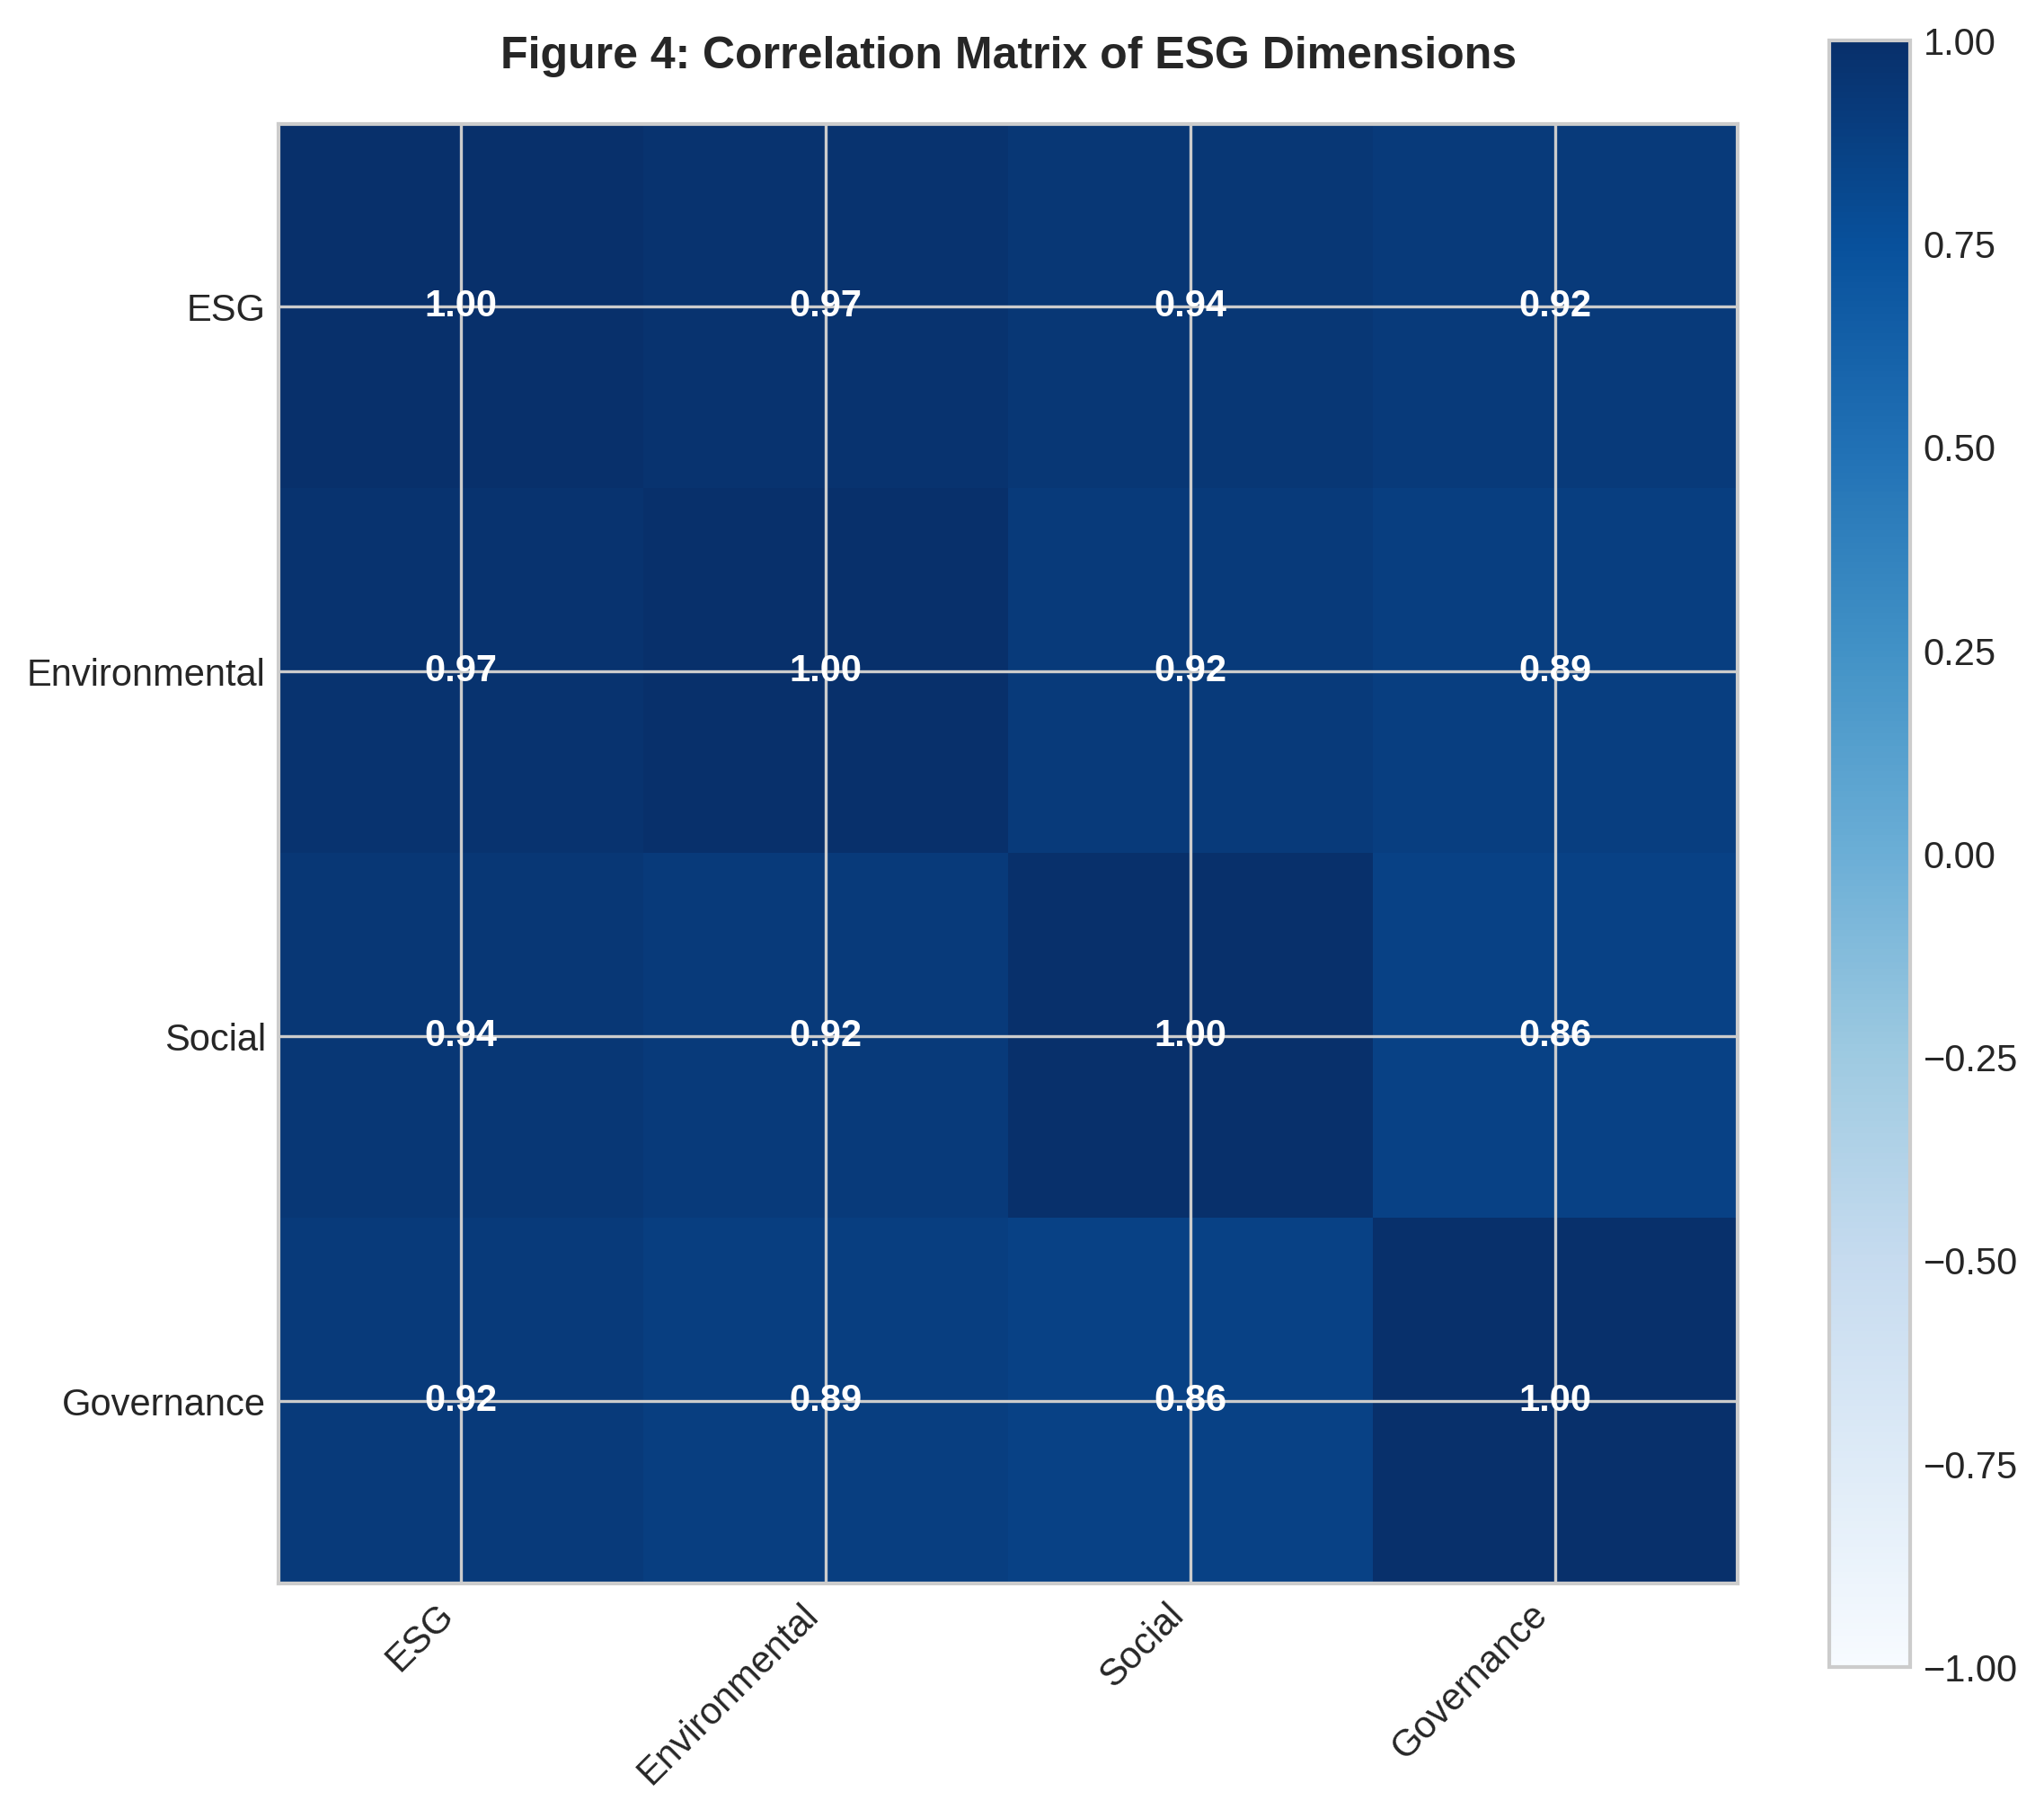

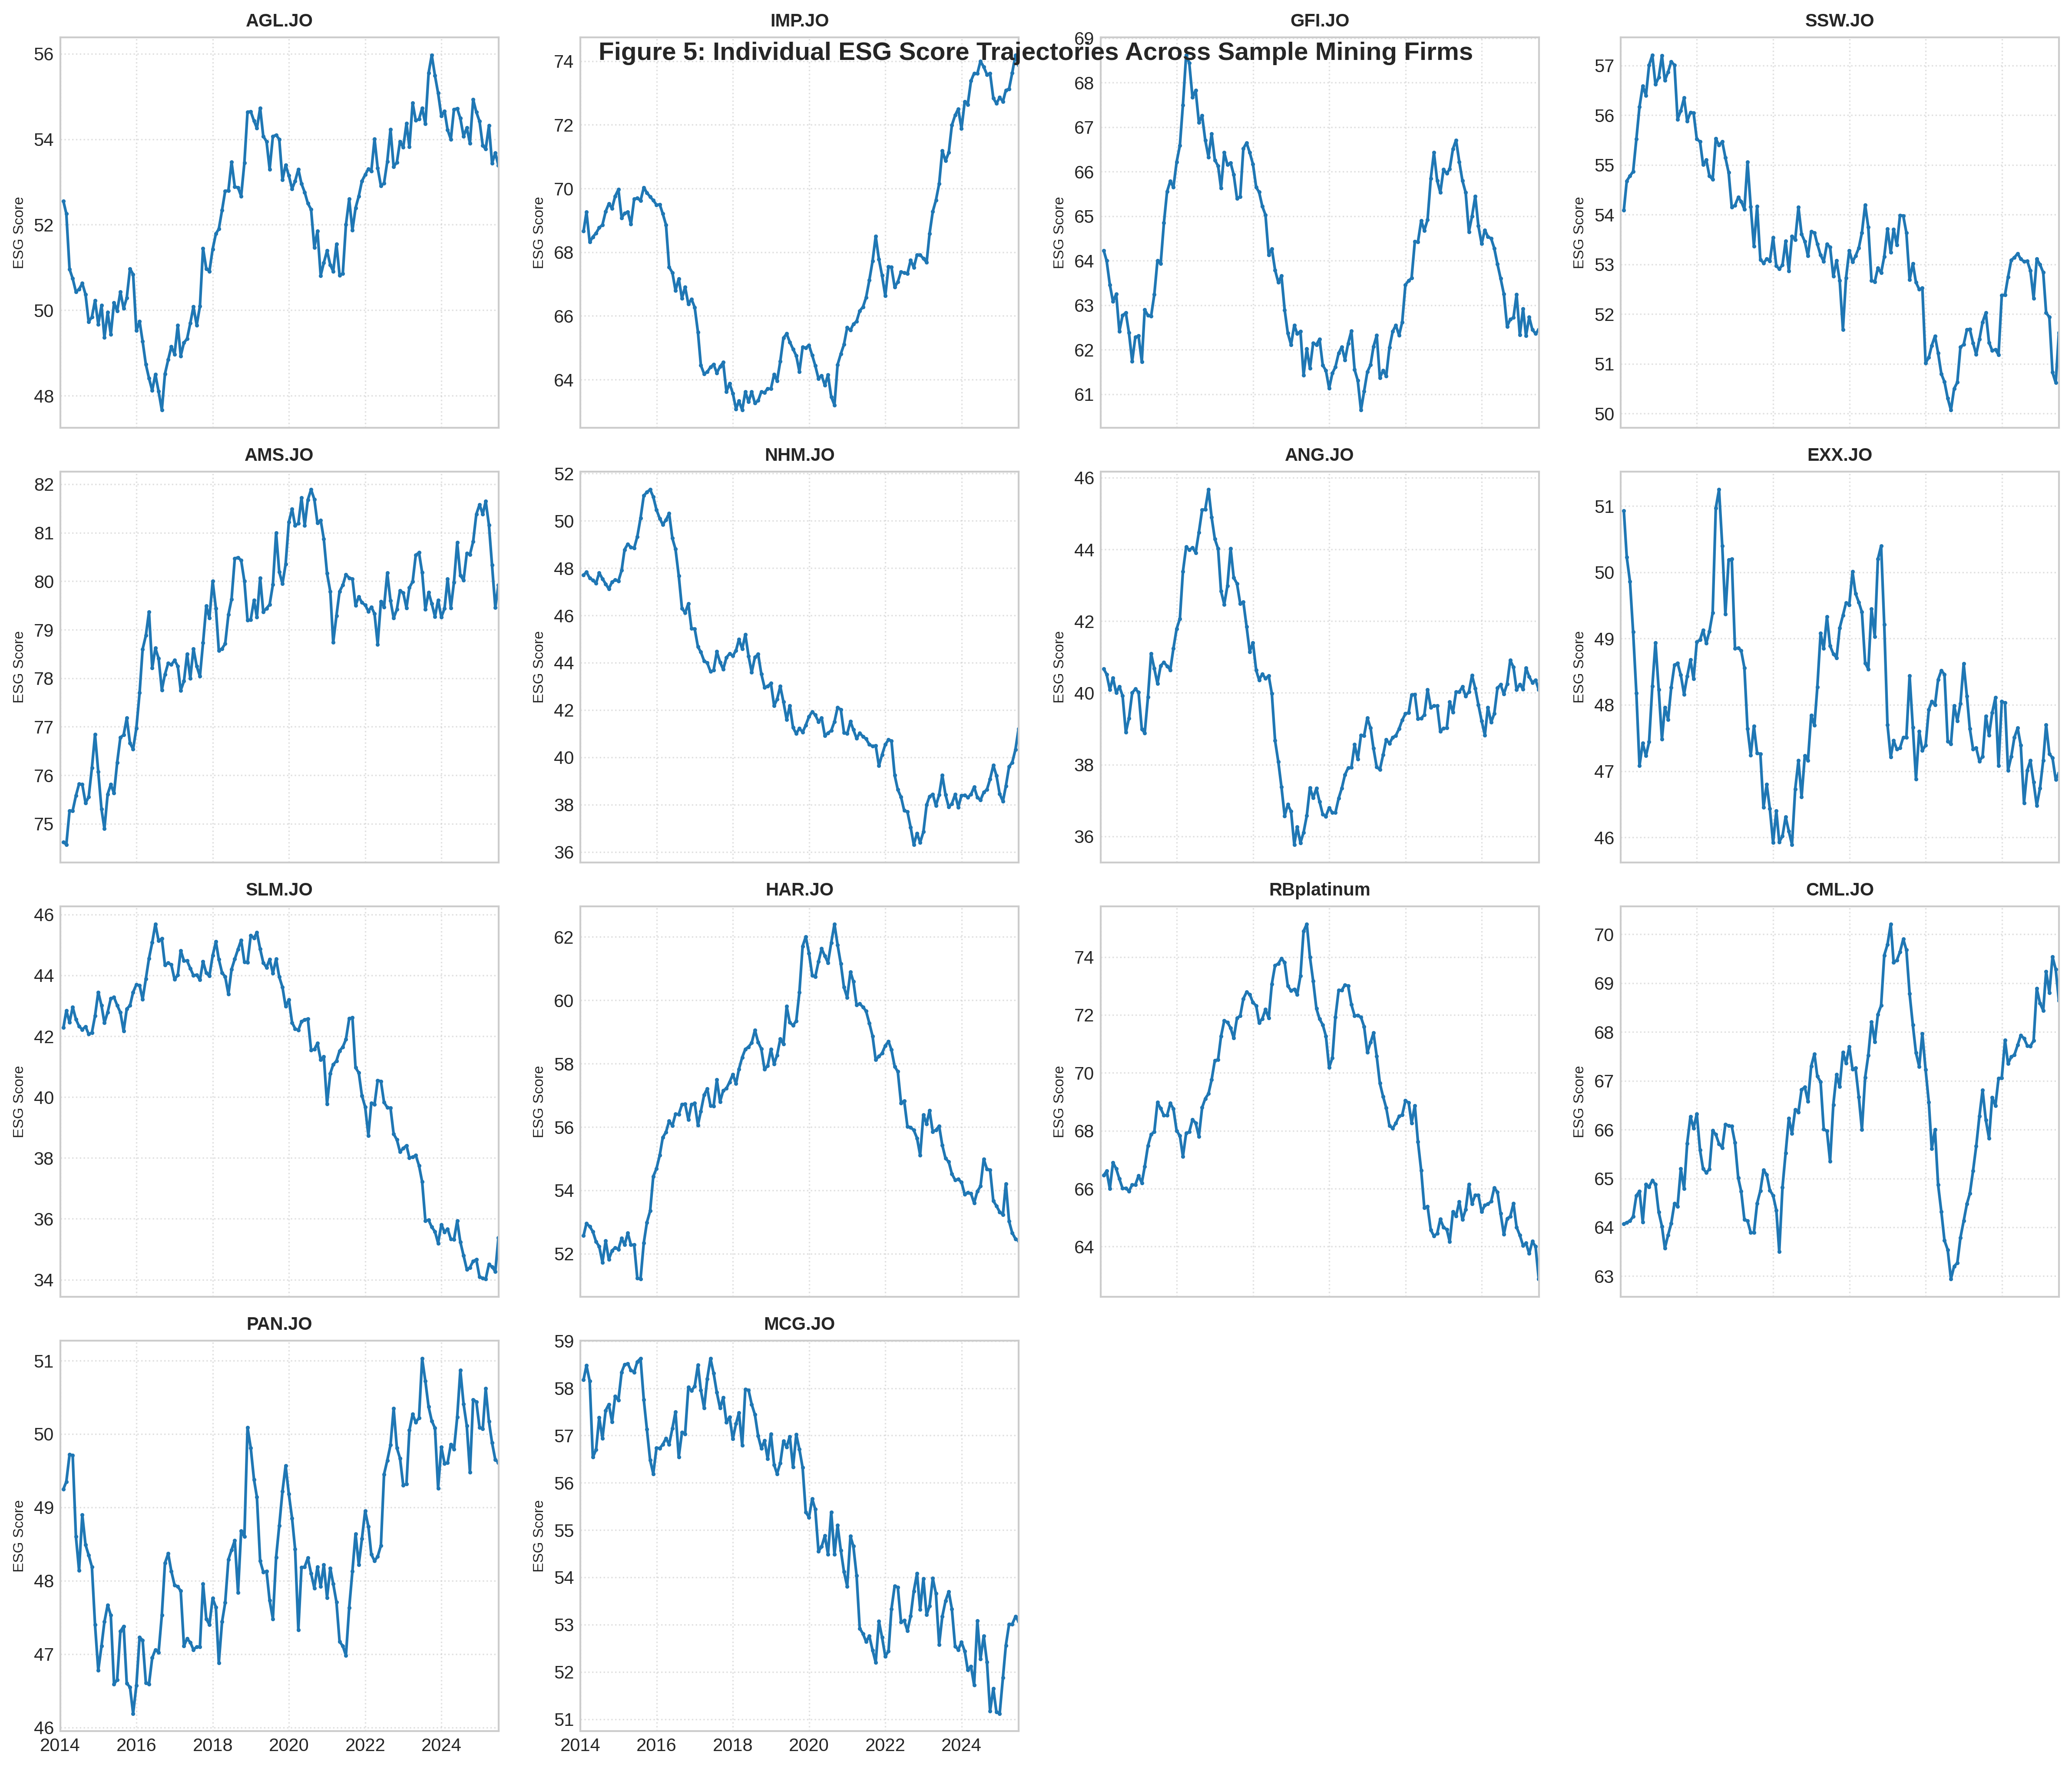

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- DATA PREPARATION ---
# Load dataset and parse datetime
df = pd.read_csv("Refinitiv_ESG_scores.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")

# Set standard plotting style
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

# ==========================================
# FIGURE 1: Longitudinal ESG Trajectories
# ==========================================
plt.figure(figsize=(12, 6), dpi=300)
for ticker, group in df.groupby("Ticker"):
  plt.plot(group["Date"], group["ESG"], label=ticker, lw=1.5)

plt.title(
    "Figure 1: Longitudinal Trajectory of ESG Scores in JSE Mining Equities",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Observation Date", fontsize=10, labelpad=10)
plt.ylabel("Composite ESG Score", fontsize=10, labelpad=10)
plt.xlim(pd.to_datetime("2014-01-01"), pd.to_datetime("2025-07-01"))
plt.legend(
    bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, facecolor="white"
)
plt.tight_layout()
plt.savefig("figure_1_esg_trajectories.png", dpi=300)
plt.show()

# ==========================================
# FIGURE 2: Sector-Wide Mean Pillar Scores
# ==========================================
mean_pillars = df.groupby("Date")[["Environmental", "Social", "Governance"]].mean()

plt.figure(figsize=(12, 6), dpi=300)
plt.plot(
    mean_pillars.index,
    mean_pillars["Environmental"],
    label="Environmental (E)",
    color="#2ca02c",
    lw=2,
)
plt.plot(
    mean_pillars.index,
    mean_pillars["Social"],
    label="Social (S)",
    color="#1f77b4",
    lw=2,
    linestyle="--",
)
plt.plot(
    mean_pillars.index,
    mean_pillars["Governance"],
    label="Governance (G)",
    color="#ff7f0e",
    lw=2,
    linestyle=":",
)

plt.title(
    "Figure 2: Sector-Wide Mean Pillar Scores Across South African Mining Firms",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Observation Date", fontsize=10, labelpad=10)
plt.ylabel("Mean Pillar Score", fontsize=10, labelpad=10)
plt.xlim(pd.to_datetime("2014-01-01"), pd.to_datetime("2025-07-01"))
plt.legend(frameon=True, facecolor="white")
plt.tight_layout()
plt.savefig("figure_2_pillar_comparison.png", dpi=300)
plt.show()

# ==========================================
# FIGURE 3: Composite ESG Box Plot Distribution
# ==========================================
plt.figure(figsize=(12, 6), dpi=300)
tickers = df["Ticker"].unique()
data_to_plot = [df[df["Ticker"] == t]["ESG"] for t in tickers]

plt.boxplot(
    data_to_plot,
    tick_labels=tickers,
    patch_artist=True,
    boxprops=dict(facecolor="#aec7e8", color="#1f77b4"),
    medianprops=dict(color="red", linewidth=1.5),
)

plt.title(
    "Figure 3: Distribution of Composite ESG Scores by Mining Equities",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Company Ticker", fontsize=10, labelpad=10)
plt.ylabel("Composite ESG Score", fontsize=10, labelpad=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("figure_3_esg_boxplot.png", dpi=300)
plt.show()

# ==========================================
# FIGURE 4: Correlation Matrix Heatmap
# ==========================================
corr = df[["ESG", "Environmental", "Social", "Governance"]].corr()

plt.figure(figsize=(8, 7), dpi=300)
cax = plt.imshow(corr, cmap="Blues", vmin=-1, vmax=1)
plt.colorbar(cax)

plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
  for j in range(len(corr.columns)):
    plt.text(
        j,
        i,
        f"{corr.iloc[i, j]:.2f}",
        ha="center",
        va="center",
        color="black" if abs(corr.iloc[i, j]) < 0.7 else "white",
        fontweight="bold",
    )

plt.title(
    "Figure 4: Correlation Matrix of ESG Dimensions",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.savefig("figure_4_correlation_heatmap.png", dpi=300)
plt.show()

# ==========================================
# FIGURE 5: Multi-Panel Subplot Grid
# ==========================================
fig, axes = plt.subplots(
    nrows=4, ncols=4, figsize=(16, 14), sharex=True, dpi=300
)
axes = axes.flatten()

for i, ticker in enumerate(tickers):
  sub_df = df[df["Ticker"] == ticker]
  axes[i].plot(
      sub_df["Date"], sub_df["ESG"], color="#1f77b4", marker="o", markersize=1.2
  )
  axes[i].set_title(f"{ticker}", fontsize=10, fontweight="bold")
  axes[i].grid(True, linestyle=":", alpha=0.6)
  axes[i].set_ylabel("ESG Score", fontsize=8)
  axes[i].set_xlim(pd.to_datetime("2014-01-01"), pd.to_datetime("2025-07-01"))

# Hide any empty subplots in the 4x4 grid
for j in range(len(tickers), len(axes)):
  fig.delaxes(axes[j])

fig.suptitle(
    "Figure 5: Individual ESG Score Trajectories Across Sample Mining Firms",
    fontsize=14,
    fontweight="bold",
    y=0.95,
)
plt.tight_layout()
plt.savefig("figure_5_multipanel_trends.png", dpi=300)
plt.show()